# Divorce Analysis — K-means cluster analysis (4.1)

This notebook clusters the **cleaned dataset** from the preprocessing notebook with k-means, chooses the number of
clusters with internal validation indices, and then checks what the clusters mean for recent divorce.

**Input:** `cleaned_dataset.parquet`, one row per person, written by `run_cleaning` in the preprocessing notebook:

| Column(s) | Meaning |
|---|---|
| `YEAR`, `PERWT`, `DIVINYR`, `split` | survey year, person weight, target (1 = divorced in past year), `train` / `test` |
| numeric (`AGE`, `INCTOT`, …) | cleaned: IPUMS codes recoded, money capped, gaps imputed; **not yet scaled** |
| `*_MISSING` | 0/1 missing-value indicator |
| categorical (`EDUC`, `OWNERSHP`, …) | pandas `category` columns, **not yet one-hot encoded** |

The leaky variables (MARST, HHTYPE, MIGRATE1) are already removed when `run_cleaning(..., exclude_situational=True)`
was used. The target, year and weight are **never** used to form clusters, only to describe them afterwards.

To produce the file, add this line at the end of `run_cleaning` in the preprocessing notebook (inside the function):

```python
fin.assign(split=np.where(train, "train", "test")).to_parquet(REPORT_DIR / "cleaned_dataset.parquet", index=False)
```

In [3]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score)

DATA_PATH = Path("divorce_cleaned.csv")
OUT_DIR = Path("report_outputs/clustering")

SEED = 0
K_RANGE = range(2, 11)      # candidate numbers of clusters
SWEEP_ROWS = 1_000_000      # training rows used to choose k (None = all training rows)
SIL_SAMPLE = 50_000         # silhouette compares every pair of rows (O(n^2)): always computed on a sample
K_FINAL = None              # None = k with the best average rank over the three indices; or set a number, e.g. 4
PLOT_ROWS = 20_000          # rows drawn in the PCA scatter
CHUNK = 500_000             # rows encoded at a time (keeps memory low)

pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#9a9a9a"

if not DATA_PATH.exists():  # also look next to the notebook and in the usual Colab / Kaggle folders
    candidates = [Path(DATA_PATH.name), Path("/content") / DATA_PATH.name, Path("/kaggle/working") / DATA_PATH.name,
                  *Path("/kaggle/input").glob(f"*/{DATA_PATH.name}")]
    found = [p for p in candidates if p.exists()]
    if not found:
        raise FileNotFoundError(f"{DATA_PATH.name} not found. Upload it or set DATA_PATH above.")
    DATA_PATH = found[0]
(OUT_DIR / "figures").mkdir(parents=True, exist_ok=True)

def save_fig(fig, name):
    fig.savefig(OUT_DIR / "figures" / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

## 1. Load the cleaned data

In [4]:
CAT_VARS = ["HHTYPE", "REGION", "STATEFIP", "METRO", "OWNERSHP", "COUPLETYPE", "SEX", "MARST",
            "MARRNO", "RACE", "EDUC", "EMPSTAT", "LABFORCE", "CLASSWKR", "WKSWORK2", "MIGRATE1"]
header = pd.read_csv(DATA_PATH, nrows=0).columns
df = pd.read_csv(DATA_PATH, keep_default_na=False,
                 dtype={c: "category" for c in CAT_VARS if c in header})
META = ["YEAR", "PERWT", "DIVINYR", "SPLIT"]
FLAG_COLS = [c for c in df.columns if c.endswith("_MISSING")]
CAT_COLS = [c for c in df.columns if isinstance(df[c].dtype, pd.CategoricalDtype)]
NUM_COLS = [c for c in df.columns if c not in META + FLAG_COLS + CAT_COLS]

leaky = [c for c in ["MARST", "HHTYPE", "MIGRATE1"] if c in df.columns]
if leaky:
    print(f"WARNING: {leaky} are still in the data. They record the divorce itself; "
          "re-run run_cleaning with exclude_situational=True.")

train = df["SPLIT"].eq("train").to_numpy()
year, y, w = df["YEAR"].to_numpy(), df["DIVINYR"].to_numpy(), df["PERWT"].to_numpy()
print(f"{DATA_PATH} | {len(df):,} rows | {int(train.sum()):,} training, {int((~train).sum()):,} test")
print(f"Numeric ({len(NUM_COLS)}): {NUM_COLS}")
print(f"Categorical ({len(CAT_COLS)}): {CAT_COLS}")
print(f"Missing indicators ({len(FLAG_COLS)}): {FLAG_COLS}")
display(df.groupby(["YEAR", "SPLIT"]).DIVINYR.agg(rows="size", divorce_rate_pct="mean")
          .assign(divorce_rate_pct=lambda t: 100 * t.divorce_rate_pct).round(2))

divorce_cleaned.csv | 5,641,835 rows | 4,513,467 training, 1,128,368 test
Numeric (11): ['AGE', 'FAMSIZE', 'NCHILD', 'UHRSWORK', 'YRMARR', 'RENT', 'VALUEH', 'INCTOT', 'FTOTINC', 'INCEARN', 'POVERTY']
Categorical (10): ['REGION', 'METRO', 'OWNERSHP', 'SEX', 'MARRNO', 'RACE', 'EDUC', 'EMPSTAT', 'CLASSWKR', 'WKSWORK2']
Missing indicators (1): ['FTOTINC_POVERTY_MISSING']


rows  divorce_rate_pct
YEAR SPLIT                           
2008 test    356811              1.26
     train  1427243              1.26
2016 test    368928              1.06
     train  1475710              1.06
2024 test    402629              0.88
     train  1610514              0.88

## 2. Feature matrix

Same rules as the preprocessing notebook: numeric columns become z-scores **within each year**, using the mean and
standard deviation of that year's **training** rows; each category level becomes one 0/1 column; missing indicators
stay 0/1. `YEAR`, `PERWT` and `DIVINYR` are left out.

In [6]:
MEAN = df.loc[train].groupby("YEAR")[NUM_COLS].mean()
SD = df.loc[train].groupby("YEAR")[NUM_COLS].std(ddof=0).replace(0, 1)

def encode(frame):
    yrs = frame["YEAR"].to_numpy()
    z = (frame[NUM_COLS].to_numpy("float64") - MEAN.loc[yrs].to_numpy()) / SD.loc[yrs].to_numpy()
    hot = pd.get_dummies(frame[CAT_COLS], prefix_sep="__", dtype="float32")  # category dtype -> every level, every time
    return np.hstack([z, frame[FLAG_COLS].to_numpy("float64"), hot.to_numpy()]).astype("float32"), list(hot.columns)

HOT_COLS = encode(df.iloc[:1])[1]
FEATURES = NUM_COLS + FLAG_COLS + HOT_COLS

def build_matrix(rows):
    X = np.empty((len(rows), len(FEATURES)), dtype="float32")
    for i in range(0, len(rows), CHUNK):
        X[i:i + CHUNK] = encode(df.iloc[rows[i:i + CHUNK]])[0]
    return X

tr_idx, te_idx = np.flatnonzero(train), np.flatnonzero(~train)
t0 = time.time()
X_tr, X_te = build_matrix(tr_idx), build_matrix(te_idx)
print(f"Training matrix {X_tr.shape}, test matrix {X_te.shape} "
      f"({(X_tr.nbytes + X_te.nbytes) / 1e9:.2f} GB), built in {time.time() - t0:.0f}s")

# k-means uses Euclidean distance, so each block's share of the total variance is its weight in the clustering
var = X_tr.var(axis=0)
blocks = {"numeric (z-scores)": slice(0, len(NUM_COLS)),
          "missing indicators": slice(len(NUM_COLS), len(NUM_COLS) + len(FLAG_COLS)),
          "one-hot columns": slice(len(NUM_COLS) + len(FLAG_COLS), len(FEATURES))}
display(pd.DataFrame({"columns": [len(range(*s.indices(len(FEATURES)))) for s in blocks.values()],
                      "share_of_total_variance_%": [100 * var[s].sum() / var.sum() for s in blocks.values()]},
                     index=blocks.keys()).round(1))

Training matrix (4513467, 67), test matrix (1128368, 67) (1.51 GB), built in 6s


,columns,share_of_total_variance_%
numeric (z-scores),11,65.900002
missing indicators,1,0.100000
one-hot columns,55,34.000000


## 3. Choosing k

Each candidate k is fitted with `MiniBatchKMeans` on a sample of training rows (fast, near-identical to full k-means)
and scored with:

| Index | Measures | Better |
|---|---|---|
| **Inertia** | sum of squared distances to the nearest centre | lower, but always falls as k grows: look for the elbow |
| **Silhouette** | how much closer each row is to its own cluster than to the next one (−1 to 1) | higher |
| **Calinski-Harabasz** | spread between clusters relative to spread within them | higher |
| **Davies-Bouldin** | average similarity of each cluster to its most similar neighbour | lower |
| **Stability (ARI)** | agreement between runs started from different seeds (1 = identical) | higher |

The silhouette compares every pair of rows, so on millions of rows it would take days; it is computed on a
random sample of `SIL_SAMPLE` rows. The other indices use every row of the sweep sample.

In [ ]:
rng = np.random.default_rng(SEED)
n_sweep = len(tr_idx) if SWEEP_ROWS is None else min(SWEEP_ROWS, len(tr_idx))
sw = np.sort(rng.choice(len(tr_idx), size=n_sweep, replace=False))
X_sw = X_tr[sw]
sil = rng.choice(n_sweep, size=min(SIL_SAMPLE, n_sweep), replace=False)

rows = []
for k in K_RANGE:
    t0 = time.time()
    runs = [MiniBatchKMeans(n_clusters=k, batch_size=10_000, n_init=3, random_state=SEED + s).fit(X_sw)
            for s in range(3)]
    best = min(runs, key=lambda m: m.inertia_)
    lab = best.labels_
    rows.append({"k": k, "inertia": best.inertia_,
                 "silhouette": silhouette_score(X_sw[sil], lab[sil]),
                 "calinski_harabasz": calinski_harabasz_score(X_sw, lab),
                 "davies_bouldin": davies_bouldin_score(X_sw, lab),
                 "stability_ARI": np.mean([adjusted_rand_score(runs[0].labels_, r.labels_) for r in runs[1:]]),
                 "seconds": time.time() - t0})
    print(f"k={k}: done in {rows[-1]['seconds']:.0f}s")
sweep = pd.DataFrame(rows).set_index("k")

rank = pd.concat([sweep.silhouette.rank(ascending=False), sweep.calinski_harabasz.rank(ascending=False),
                  sweep.davies_bouldin.rank(ascending=True)], axis=1).mean(axis=1)
sweep["mean_rank"] = rank
best_by = {"silhouette": sweep.silhouette.idxmax(), "Calinski-Harabasz": sweep.calinski_harabasz.idxmax(),
           "Davies-Bouldin": sweep.davies_bouldin.idxmin()}
K = int(K_FINAL) if K_FINAL is not None else int(rank.idxmin())
print(f"Swept on {n_sweep:,} training rows; silhouette on {len(sil):,} of them.")
if sweep.loc[K, "stability_ARI"] < 0.6:
    print(f"WARNING: at k = {K}, runs from different seeds agree poorly (ARI = {sweep.loc[K, 'stability_ARI']:.2f}). "
          "These clusters depend on the starting point; consider a k with higher stability and set K_FINAL.")
print("Best k per index:", best_by, f"-> k = {K}" + (" (set by hand)" if K_FINAL is not None else " (best average rank)"))
display(sweep.round(3))

k=2: done in 37s
k=3: done in 42s
k=4: done in 36s
k=5: done in 34s
k=6: done in 31s
k=7: done in 34s
k=8: done in 34s
k=9: done in 30s
k=10: done in 31s
Swept on 1,000,000 training rows; silhouette on 50,000 of them.
Best k per index: {'silhouette': np.int64(2), 'Calinski-Harabasz': np.int64(2), 'Davies-Bouldin': np.int64(2)} -> k = 2 (best average rank)


,inertia,silhouette,calinski_harabasz,davies_bouldin,stability_ARI,seconds,mean_rank
k,,,,,,,
2,13395692.0,0.188,246402.312,1.892,0.971,36.589,1.000
3,12052803.0,0.165,192818.359,2.102,0.717,41.680,3.333
4,11180455.0,0.168,164485.344,1.984,0.530,36.201,2.667
5,10521868.0,0.150,148110.312,1.899,0.498,33.858,3.333
6,10004019.0,0.119,133910.359,2.131,0.669,31.370,5.333
7,9695204.0,0.117,120866.938,2.079,0.628,33.890,5.333
8,9393104.0,0.104,111233.664,2.138,0.577,34.344,7.000
9,9098946.0,0.097,104411.859,2.159,0.483,30.479,8.000
10,8884324.0,0.090,97759.688,2.163,0.537,30.828,9.000


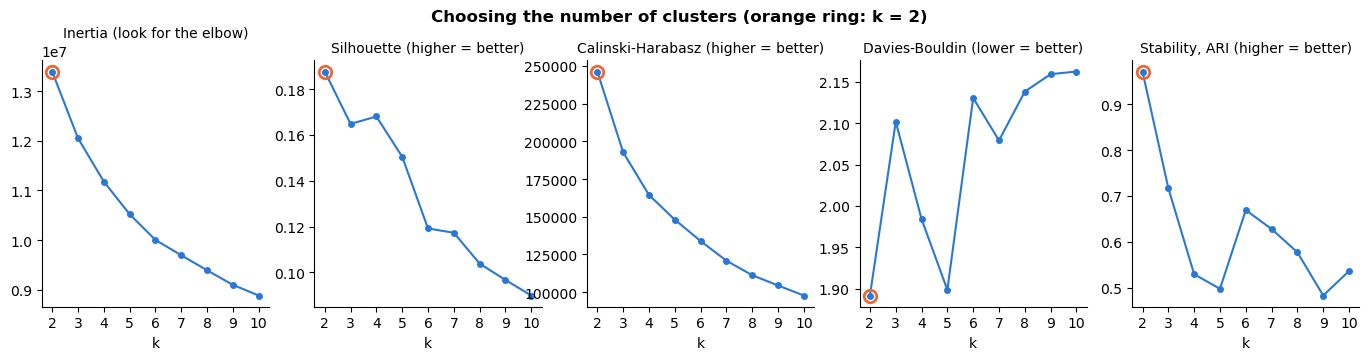

In [ ]:
panels = [("inertia", "Inertia (look for the elbow)"), ("silhouette", "Silhouette (higher = better)"),
          ("calinski_harabasz", "Calinski-Harabasz (higher = better)"),
          ("davies_bouldin", "Davies-Bouldin (lower = better)"), ("stability_ARI", "Stability, ARI (higher = better)")]
fig, axes = plt.subplots(1, 5, figsize=(17, 3.2))
for ax, (col, title) in zip(axes, panels):
    ax.plot(sweep.index, sweep[col], color=BLUE, marker="o", ms=4)
    ax.plot(K, sweep.loc[K, col], marker="o", ms=9, mfc="none", mec=ORANGE, mew=2)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("k")
    ax.set_xticks(list(sweep.index))
fig.suptitle(f"Choosing the number of clusters (orange ring: k = {K})", fontweight="bold", y=1.04)
save_fig(fig, "kmeans_choose_k")

## 4. Final model

Full k-means (Lloyd's algorithm) with the chosen k on **all** training rows. Test rows are then assigned to the
nearest centre: if the indices are similar on both, the clusters are not an artefact of the training sample.

In [10]:
rng = np.random.default_rng(SEED)
K=3
t0 = time.time()
km = KMeans(n_clusters=K, n_init=3, random_state=SEED).fit(X_tr)
lab_tr, lab_te = km.labels_, km.predict(X_te)
print(f"KMeans k={K} on {len(X_tr):,} rows: {time.time() - t0:.0f}s, {km.n_iter_} iterations")

# Calinski-Harabasz grows with the number of rows, so train and test are scored on samples of the same size
n_eval = min(len(X_tr), len(X_te))

def scores(X, lab):
    e = rng.choice(len(X), size=n_eval, replace=False)
    s = e[:min(SIL_SAMPLE, n_eval)]
    return {"rows": n_eval, "silhouette (sample)": silhouette_score(X[s], lab[s]),
            "calinski_harabasz": calinski_harabasz_score(X[e], lab[e]),
            "davies_bouldin": davies_bouldin_score(X[e], lab[e])}

final_scores = pd.DataFrame({"train": scores(X_tr, lab_tr), "test": scores(X_te, lab_te)}).T
display(final_scores.round(3))

KMeans k=3 on 4,513,467 rows: 42s, 26 iterations


,rows,silhouette (sample),calinski_harabasz,davies_bouldin
train,1128368.0,0.166,220054.469,1.968
test,1128368.0,0.166,220137.609,1.968


## 5. What the clusters mean

The divorce rates are weighted with `PERWT`, so they compare directly with the population rate. A cluster well
above the overall rate is a group with a high share of recent divorces.

Overall weighted divorce rate (training rows): 1.24%


,share_of_rows_%,divorce_rate_train_%,divorce_rate_test_%,times_overall_rate
cluster,,,,
0,45.58,1.81,1.80,1.46
1,38.37,0.59,0.60,0.48
2,16.06,0.83,0.82,0.67


Weighted divorce rate (%) by cluster and year:


,2008,2016,2024
cluster,,,
0,2.16,1.78,1.48
1,0.66,0.61,0.52
2,1.01,0.78,0.71


Share of each cluster's rows from each year (%):


,2008,2016,2024
cluster,,,
0,33.6,32.4,33.9
1,28.9,32.9,38.2
2,32.6,32.9,34.6


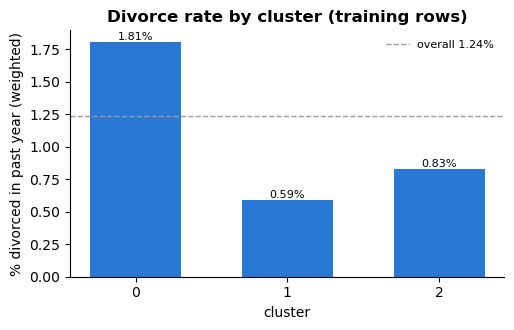

In [11]:
K=3
def wrate(mask):
    return 100 * np.average(y[mask], weights=w[mask]) if mask.any() else np.nan

overall = wrate(train)
cluster_all = np.full(len(df), -1)
cluster_all[tr_idx], cluster_all[te_idx] = lab_tr, lab_te
profile = pd.DataFrame({
    "share_of_rows_%": [100 * (lab_tr == c).mean() for c in range(K)],
    "divorce_rate_train_%": [wrate(train & (cluster_all == c)) for c in range(K)],
    "divorce_rate_test_%": [wrate(~train & (cluster_all == c)) for c in range(K)],
}, index=pd.Index(range(K), name="cluster"))
profile["times_overall_rate"] = profile["divorce_rate_train_%"] / overall
print(f"Overall weighted divorce rate (training rows): {overall:.2f}%")
display(profile.round(2))

by_year = pd.DataFrame({yr: [wrate(train & (cluster_all == c) & (year == yr)) for c in range(K)]
                        for yr in sorted(np.unique(year))}, index=profile.index)
year_mix = pd.crosstab(lab_tr, year[tr_idx], normalize="index").mul(100)
year_mix.index.name, year_mix.columns.name = "cluster", None
print("Weighted divorce rate (%) by cluster and year:"); display(by_year.round(2))
print("Share of each cluster's rows from each year (%):"); display(year_mix.round(1))

fig, ax = plt.subplots(figsize=(1.2 * K + 2, 3.2))
ax.bar(profile.index.astype(str), profile["divorce_rate_train_%"], color=BLUE, width=0.6)
ax.axhline(overall, color=GREY, ls="--", lw=1, label=f"overall {overall:.2f}%")
for c, v in profile["divorce_rate_train_%"].items():
    ax.text(c, v, f"{v:.2f}%", ha="center", va="bottom", fontsize=8)
ax.set_xlabel("cluster"); ax.set_ylabel("% divorced in past year (weighted)")
ax.set_title("Divorce rate by cluster (training rows)", fontweight="bold"); ax.legend(frameon=False, fontsize=8)
save_fig(fig, "kmeans_divorce_rate_by_cluster")

**Cluster centres.** Numeric centres are in standard deviations from that year's average (0 = average). For the
categorical variables, the table lists the levels that are most over-represented in each cluster compared with
all training rows (in percentage points).

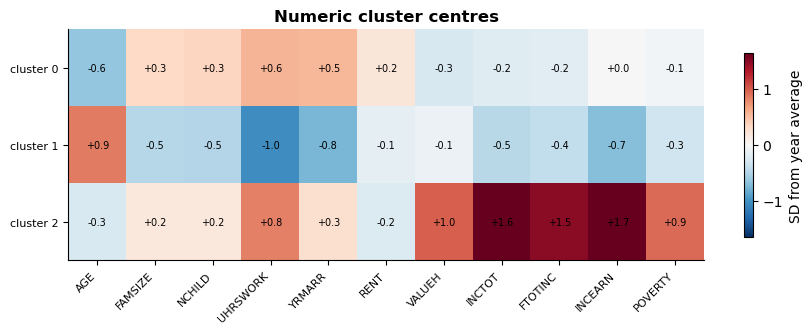

,most over-represented levels
cluster,
0,EMPSTAT = Employed (+30 pts); WKSWORK2 = 50-52 weeks (+25 pts); CLASSWKR = Works for wages (+24 pts); OWNERSHP = Rented (+8 pts)
1,WKSWORK2 = N/A (+51 pts); EMPSTAT = Not in labor force (+51 pts); CLASSWKR = N/A (+41 pts); EDUC = Grade 12 (+8 pts)
2,WKSWORK2 = 50-52 weeks (+37 pts); EMPSTAT = Employed (+36 pts); CLASSWKR = Works for wages (+21 pts); EDUC = 5+ years of college (+21 pts)


In [12]:
K = 3
centres = pd.DataFrame(km.cluster_centers_, columns=FEATURES)
num_c = centres[NUM_COLS]
fig, ax = plt.subplots(figsize=(0.75 * len(NUM_COLS) + 2, 0.5 * K + 1.5))
lim = max(1.0, float(np.abs(num_c.to_numpy()).max()))
im = ax.imshow(num_c.to_numpy(), cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(len(NUM_COLS)), NUM_COLS, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(K), [f"cluster {c}" for c in range(K)], fontsize=8)
for i in range(K):
    for j in range(len(NUM_COLS)):
        ax.text(j, i, f"{num_c.iat[i, j]:+.1f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.8, label="SD from year average")
ax.set_title("Numeric cluster centres", fontweight="bold")
save_fig(fig, "kmeans_numeric_centres")

hot_share = centres[HOT_COLS] - X_tr[:, len(NUM_COLS) + len(FLAG_COLS):].mean(axis=0)
top_levels = pd.DataFrame({
    "most over-represented levels": [
        "; ".join(f"{name.replace('__', ' = ')} ({100 * d:+.0f} pts)"
                  for name, d in hot_share.iloc[c].sort_values(ascending=False).head(4).items())
        for c in range(K)]}, index=profile.index)
with pd.option_context("display.max_colwidth", None):
    display(top_levels)

In [13]:
K = 3
# Clusters in original units (training rows). Values are cleaned (capped, imputed) but not scaled.
tr_df = df.loc[train].assign(cluster=lab_tr)

# 1. Numeric: median per cluster
num_tab = tr_df.groupby("cluster")[NUM_COLS].median().T
num_tab["all"] = tr_df[NUM_COLS].median()

# hours, rent and house value are 0 for people they don't apply to (non-workers, owners, renters),
# so the plain median can be 0: also show the median among people who have a value, and how many do
for c in [c for c in ["UHRSWORK", "RENT", "VALUEH"] if c in NUM_COLS]:
    has = tr_df[c] > 0
    med = tr_df[has].groupby("cluster")[c].median(); med["all"] = tr_df.loc[has, c].median()
    pct = has.groupby(tr_df["cluster"]).mean() * 100; pct["all"] = has.mean() * 100
    num_tab.loc[f"{c} (median where > 0)"] = med
    num_tab.loc[f"{c}: % with a value"] = pct
num_tab.columns = [f"cluster {c}" if c != "all" else "all rows" for c in num_tab.columns]
print("Median per cluster, original units:")
display(num_tab.round(1))

# 2. Categorical: share of each level in the cluster vs in all rows
cat_rows = []
for v in CAT_COLS:
    overall = tr_df[v].value_counts(normalize=True) * 100
    share = pd.crosstab(tr_df[v], tr_df["cluster"], normalize="columns") * 100
    for c in share.columns:
        for lvl in share.index:
            cat_rows.append({"cluster": c, "variable": v, "level": lvl,
                             "share_in_cluster_%": share.at[lvl, c], "share_all_rows_%": overall[lvl]})
cat_tab = pd.DataFrame(cat_rows)
cat_tab["difference_pts"] = cat_tab["share_in_cluster_%"] - cat_tab["share_all_rows_%"]
top = (cat_tab.sort_values("difference_pts", ascending=False).groupby("cluster").head(8)
              .sort_values(["cluster", "difference_pts"], ascending=[True, False]))
print("Most over-represented levels per cluster:")
display(top.round(1).reset_index(drop=True))

# 3. Full breakdown of any one variable across clusters
def level_table(v):
    t = pd.crosstab(tr_df[v], tr_df["cluster"], normalize="columns").mul(100)
    t.columns = [f"cluster {c}" for c in t.columns]
    t["all rows"] = tr_df[v].value_counts(normalize=True).mul(100)
    return t.round(1)

display(level_table("EMPSTAT"))
display(level_table("EDUC"))

num_tab.to_csv(OUT_DIR / "kmeans_numeric_medians.csv")
cat_tab.to_csv(OUT_DIR / "kmeans_level_shares.csv", index=False)
del tr_df

Median per cluster, original units:


,cluster 0,cluster 1,cluster 2,all rows
AGE,45.0,70.0,52.0,56.0
FAMSIZE,3.0,2.0,3.0,2.0
NCHILD,1.0,0.0,1.0,0.0
UHRSWORK,40.0,0.0,40.0,32.0
YRMARR,2000.0,1976.0,1995.0,1992.0
RENT,0.0,0.0,0.0,0.0
VALUEH,135000.0,150000.0,450000.0,180000.0
INCTOT,35000.0,16800.0,116000.0,32700.0
FTOTINC,75500.0,50900.0,198830.0,76000.0
INCEARN,33000.0,0.0,100000.0,16000.0


Most over-represented levels per cluster:


,cluster,variable,level,share_in_cluster_%,share_all_rows_%,difference_pts
0,0,EMPSTAT,Employed,86.6,56.9,29.7
1,0,WKSWORK2,50-52 weeks,74.5,49.2,25.3
2,0,CLASSWKR,Works for wages,85.9,61.6,24.2
3,0,OWNERSHP,Rented,27.3,19.0,8.4
4,0,MARRNO,Married once,76.9,74.7,2.2
5,0,EDUC,2 years of college,10.6,8.5,2.1
6,0,EDUC,1 year of college,15.0,13.1,1.9
7,0,WKSWORK2,40-47 weeks,5.1,3.3,1.8
8,1,EMPSTAT,Not in labor force,92.1,41.1,51.0
9,1,WKSWORK2,N/A,89.5,38.5,51.0


,cluster 0,cluster 1,cluster 2,all rows
EMPSTAT,,,,
Employed,86.6,6.5,93.0,56.9
Not in labor force,10.4,92.1,6.2,41.1
Unemployed,3.0,1.4,0.8,2.0


,cluster 0,cluster 1,cluster 2,all rows
EDUC,,,,
1 year of college,15.0,12.5,9.4,13.1
2 years of college,10.6,6.8,6.8,8.5
4 years of college,18.9,13.7,34.6,19.4
5+ years of college,9.4,9.3,34.4,13.4
Grade 10,1.4,2.5,0.3,1.6
Grade 11,1.6,2.5,0.3,1.7
Grade 12,37.9,43.8,13.4,36.2
"Grade 5, 6, 7, or 8",2.3,4.3,0.3,2.7
Grade 9,1.2,1.8,0.1,1.3


## 6. Visualisation (PCA, 2D)

The clusters live in all feature dimensions; this projects a sample of training rows onto the first two principal
components only to show them. Overlap in 2D does not by itself mean the clusters overlap in the full space.

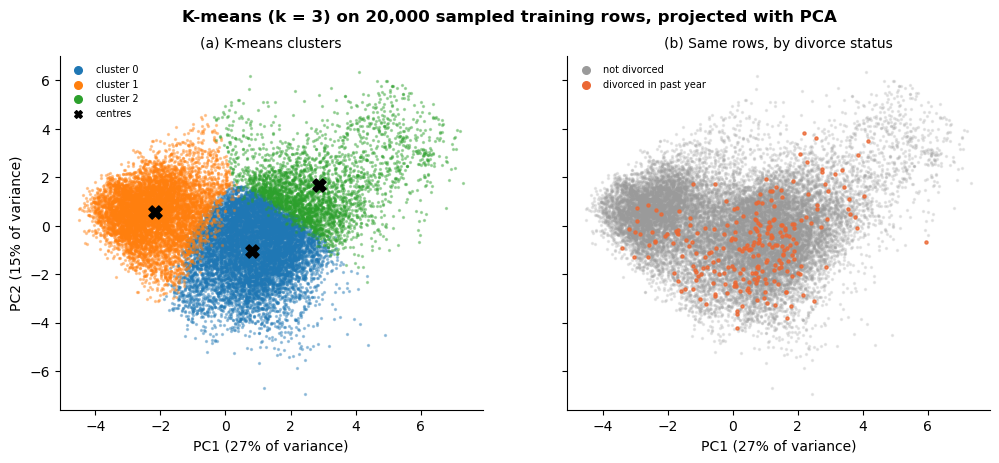

In [14]:
K = 3
s = rng.choice(len(X_tr), size=min(PLOT_ROWS, len(X_tr)), replace=False)
pca = PCA(n_components=2, random_state=SEED).fit(X_tr[s])
pcs = pca.transform(X_tr[s])
ev = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharex=True, sharey=True)
cmap = plt.get_cmap("tab10")
for c in range(K):
    m = lab_tr[s] == c
    axes[0].scatter(pcs[m, 0], pcs[m, 1], s=2, alpha=0.35, color=cmap(c % 10), label=f"cluster {c}")
cen = pca.transform(km.cluster_centers_)
axes[0].scatter(cen[:, 0], cen[:, 1], marker="X", s=90, color="black", label="centres")
leg = axes[0].legend(fontsize=7, frameon=False)
for h in getattr(leg, "legend_handles", getattr(leg, "legendHandles", [])):
    h.set_sizes([30]); h.set_alpha(1)
axes[0].set_title("(a) K-means clusters", fontsize=10)
d = y[tr_idx][s] == 1
axes[1].scatter(pcs[~d, 0], pcs[~d, 1], s=2, alpha=0.2, color=GREY, label="not divorced")
axes[1].scatter(pcs[d, 0], pcs[d, 1], s=5, alpha=0.8, color=ORANGE, label="divorced in past year")
leg = axes[1].legend(fontsize=7, frameon=False)
for h in getattr(leg, "legend_handles", getattr(leg, "legendHandles", [])):
    h.set_sizes([30]); h.set_alpha(1)
axes[1].set_title("(b) Same rows, by divorce status", fontsize=10)
for ax in axes:
    ax.set_xlabel(f"PC1 ({100 * ev[0]:.0f}% of variance)")
axes[0].set_ylabel(f"PC2 ({100 * ev[1]:.0f}% of variance)")
fig.suptitle(f"K-means (k = {K}) on {len(s):,} sampled training rows, projected with PCA", fontweight="bold")
save_fig(fig, "kmeans_pca_scatter")

## 7. Outlier detection: cluster-based (Aggarwal 8.4)

Each person's outlier score is their distance to the nearest k-means centre, divided by the median distance in
that cluster (some clusters are naturally wider). This uses separate models with more clusters (k = 10, 20, 40)
than the k = 2 analysis above: with many small clusters, a high score means "unlike any common profile". The
final score is the average over the three values of k, and the top 1% of training scores are the outliers. The
same threshold is applied to the test rows. Clusters holding under 0.1% of rows are reported as possible groups
of outliers.

In [16]:
OUT_KS = (10, 20, 40)        # several k: the final score is their average (more robust than one k)
OUT_SHARE = 0.01             # top 1% of training scores = outliers
SMALL_CLUSTER = 0.001        # clusters with < 0.1% of training rows = possible collective outliers

def nearest_centre(model, X):
    """Distance to the nearest centre and that centre's index, in chunks to keep memory low."""
    dist, lab = np.empty(len(X), "float32"), np.empty(len(X), "int32")
    for i in range(0, len(X), CHUNK):
        D = model.transform(X[i:i + CHUNK])
        lab[i:i + CHUNK], dist[i:i + CHUNK] = D.argmin(axis=1), D.min(axis=1)
    return dist, lab

scores_tr, scores_te, small_rows = {}, {}, []
for k in OUT_KS:
    t0 = time.time()
    m = MiniBatchKMeans(n_clusters=k, batch_size=10_000, n_init=3, random_state=SEED).fit(X_tr)
    d_tr, l_tr = nearest_centre(m, X_tr)
    d_te, l_te = nearest_centre(m, X_te)
    # relative distance: divide by the median distance in that cluster (some clusters are naturally wider)
    scale = pd.Series(d_tr).groupby(l_tr).median().reindex(range(k)).to_numpy()
    scale = np.where(np.isfinite(scale) & (scale > 0), scale, np.median(d_tr))
    scores_tr[k], scores_te[k] = d_tr / scale[l_tr], d_te / scale[l_te]
    size = np.bincount(l_tr, minlength=k) / len(l_tr)
    tiny = np.flatnonzero(size < SMALL_CLUSTER)
    small_rows.append({"k": k, "clusters_below_0.1%": len(tiny), "rows_in_them": int(np.isin(l_tr, tiny).sum())})
    print(f"k={k}: fitted and scored in {time.time() - t0:.0f}s")

score_tr = np.mean([scores_tr[k] for k in OUT_KS], axis=0)
score_te = np.mean([scores_te[k] for k in OUT_KS], axis=0)
threshold = np.quantile(score_tr, 1 - OUT_SHARE)
out_tr, out_te = score_tr >= threshold, score_te >= threshold
print(f"Threshold (top {OUT_SHARE:.0%} of training scores): {threshold:.2f} | "
      f"outliers: {out_tr.mean():.2%} of training rows, {out_te.mean():.2%} of test rows")
print("Tiny clusters (possible groups of outliers):"); display(pd.DataFrame(small_rows).set_index("k"))

# stability: how much the top-1% lists agree between values of k (Jaccard, 1 = identical lists)
tops = {k: scores_tr[k] >= np.quantile(scores_tr[k], 1 - OUT_SHARE) for k in OUT_KS}
jac = pd.DataFrame([[(tops[a] & tops[b]).sum() / (tops[a] | tops[b]).sum() for b in OUT_KS] for a in OUT_KS],
                   index=[f"k={k}" for k in OUT_KS], columns=[f"k={k}" for k in OUT_KS])
print("Overlap of the top-1% lists between values of k (Jaccard):"); display(jac.round(2))

k=10: fitted and scored in 13s
k=20: fitted and scored in 33s
k=40: fitted and scored in 31s
Threshold (top 1% of training scores): 1.63 | outliers: 1.00% of training rows, 1.00% of test rows
Tiny clusters (possible groups of outliers):


,clusters_below_0.1%,rows_in_them
k,,
10,0,0
20,0,0
40,0,0


Overlap of the top-1% lists between values of k (Jaccard):


,k=10,k=20,k=40
k=10,1.00,0.22,0.17
k=20,0.22,1.00,0.30
k=40,0.17,0.30,1.00


In [17]:
is_out = np.zeros(len(df), dtype=bool)
is_out[tr_idx], is_out[te_idx] = out_tr, out_te
score_all = np.empty(len(df), dtype="float32")
score_all[tr_idx], score_all[te_idx] = score_tr, score_te

# 1. Noise or information? Weighted divorce rate among outliers vs everyone else
rates = pd.DataFrame({
    "outliers_%_of_rows": [100 * out_tr.mean(), 100 * out_te.mean()],
    "divorce_rate_outliers_%": [wrate(train & is_out), wrate(~train & is_out)],
    "divorce_rate_rest_%": [wrate(train & ~is_out), wrate(~train & ~is_out)]}, index=["train", "test"])
rates["ratio"] = rates["divorce_rate_outliers_%"] / rates["divorce_rate_rest_%"]
print("Weighted divorce rate, outliers vs the rest:"); display(rates.round(2))
by_year_out = pd.DataFrame({yr: {"outliers": wrate(train & is_out & (year == yr)),
                                 "rest": wrate(train & ~is_out & (year == yr))} for yr in sorted(np.unique(year))})
print("By year (training rows):"); display(by_year_out.round(2))

# 2. Who are the outliers? Original units, training rows
tr_df = df.loc[train].assign(outlier=out_tr)
med = tr_df.groupby("outlier")[NUM_COLS].median().T.rename(columns={False: "rest", True: "outliers"})
print("Median, outliers vs the rest:"); display(med.round(1))
if FLAG_COLS:
    print("% with missing-value flag:")
    display((tr_df.groupby("outlier")[FLAG_COLS].mean().T * 100).rename(columns={False: "rest", True: "outliers"}).round(1))
lv = []
for v in CAT_COLS:
    sh = pd.crosstab(tr_df[v], tr_df["outlier"], normalize="columns") * 100
    for lvl in sh.index:
        lv.append({"variable": v, "level": lvl, "share_outliers_%": sh.at[lvl, True], "share_rest_%": sh.at[lvl, False]})
lv = pd.DataFrame(lv)
lv["difference_pts"] = lv["share_outliers_%"] - lv["share_rest_%"]
print("Most over-represented levels among outliers:")
display(lv.sort_values("difference_pts", ascending=False).head(10).round(1).reset_index(drop=True))
del tr_df

Weighted divorce rate, outliers vs the rest:


,outliers_%_of_rows,divorce_rate_outliers_%,divorce_rate_rest_%,ratio
train,1.0,1.24,1.24,1.00
test,1.0,1.15,1.24,0.93


By year (training rows):


,2008,2016,2024
outliers,1.48,1.26,1.05
rest,1.50,1.22,1.03


Median, outliers vs the rest:


outlier,rest,outliers
AGE,56.0,52.0
FAMSIZE,2.0,4.0
NCHILD,0.0,1.0
UHRSWORK,32.0,9.0
YRMARR,1992.0,1995.0
RENT,0.0,0.0
VALUEH,180000.0,85000.0
INCTOT,32500.0,50000.0
FTOTINC,75800.0,200000.0
INCEARN,16400.0,1700.0


% with missing-value flag:


outlier,rest,outliers
FTOTINC_POVERTY_MISSING,2.5,1.3


Most over-represented levels among outliers:


,variable,level,share_outliers_%,share_rest_%,difference_pts
0,OWNERSHP,Rented,44.3,18.7,25.6
1,REGION,Pacific Division,31.2,15.0,16.2
2,METRO,In metropolitan area: In central/principal city,20.3,10.0,10.3
3,EMPSTAT,Not in labor force,51.2,41.0,10.2
4,WKSWORK2,N/A,47.8,38.4,9.3
5,CLASSWKR,N/A,38.5,29.2,9.3
6,EDUC,5+ years of college,22.5,13.3,9.3
7,CLASSWKR,Self-employed,15.1,9.0,6.2
8,RACE,Other Asian or Pacific Islander,9.3,3.7,5.6
9,MARRNO,Married once,79.2,74.6,4.6


Text(0.5, 0.98, 'Cluster-based outlier detection (training rows)')

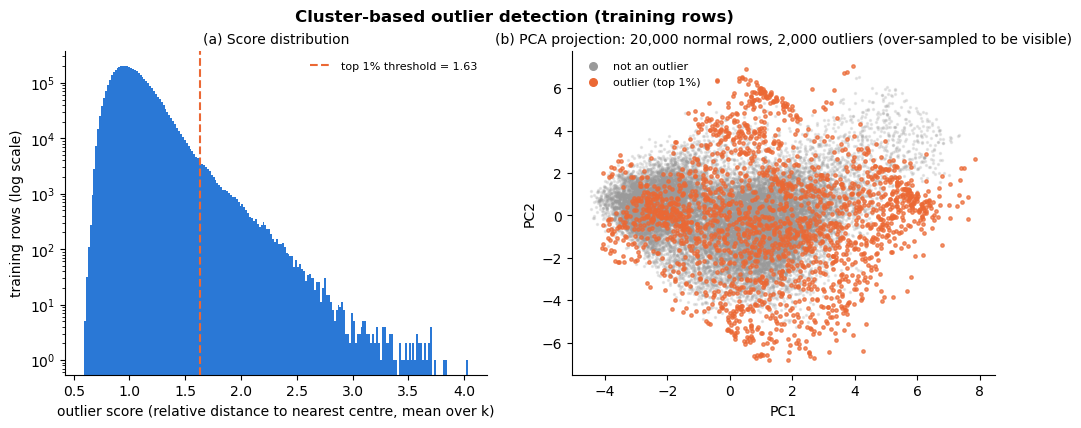

In [ ]:
r = np.random.default_rng(SEED)
if "pca" not in globals():
    pca = PCA(n_components=2, random_state=SEED).fit(X_tr[r.choice(len(X_tr), 20_000, replace=False)])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].hist(score_tr, bins=200, color=BLUE, log=True)
axes[0].axvline(threshold, color=ORANGE, ls="--", lw=1.5, label=f"top {OUT_SHARE:.0%} threshold = {threshold:.2f}")
axes[0].set_xlabel("outlier score (relative distance to nearest centre, mean over k)")
axes[0].set_ylabel("training rows (log scale)")
axes[0].legend(frameon=False, fontsize=8)
axes[0].set_title("(a) Score distribution", fontsize=10)

normal_s = r.choice(np.flatnonzero(~out_tr), size=min(20_000, int((~out_tr).sum())), replace=False)
out_s = r.choice(np.flatnonzero(out_tr), size=min(2_000, int(out_tr.sum())), replace=False)
p_n, p_o = pca.transform(X_tr[normal_s]), pca.transform(X_tr[out_s])
axes[1].scatter(p_n[:, 0], p_n[:, 1], s=2, alpha=0.2, color=GREY, label="not an outlier")
axes[1].scatter(p_o[:, 0], p_o[:, 1], s=6, alpha=0.7, color=ORANGE, label=f"outlier (top {OUT_SHARE:.0%})")
leg = axes[1].legend(fontsize=8, frameon=False)
for h in getattr(leg, "legend_handles", getattr(leg, "legendHandles", [])):
    h.set_sizes([30]); h.set_alpha(1)
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
axes[1].set_title(f"(b) PCA projection: {len(normal_s):,} normal rows, {len(out_s):,} outliers (over-sampled to be visible)",
                  fontsize=10)
fig.suptitle("Cluster-based outlier detection (training rows)", fontweight="bold")

# save_fig(fig, "outliers_cluster_based")

# rates.to_csv(OUT_DIR / "outliers_divorce_rate.csv")
# jac.to_csv(OUT_DIR / "outliers_overlap_between_k.csv")
# med.to_csv(OUT_DIR / "outliers_numeric_medians.csv")
# lv.to_csv(OUT_DIR / "outliers_level_shares.csv", index=False)
# pd.DataFrame({"row": np.arange(len(df)), "split": df["split"], "outlier_score": score_all,
#               "is_outlier": is_out}).to_csv(OUT_DIR / "outlier_scores.csv", index=False)
# print("Saved to", OUT_DIR.resolve())

Text(0.5, 1.0, 'Outliers: high family income, low own earnings')

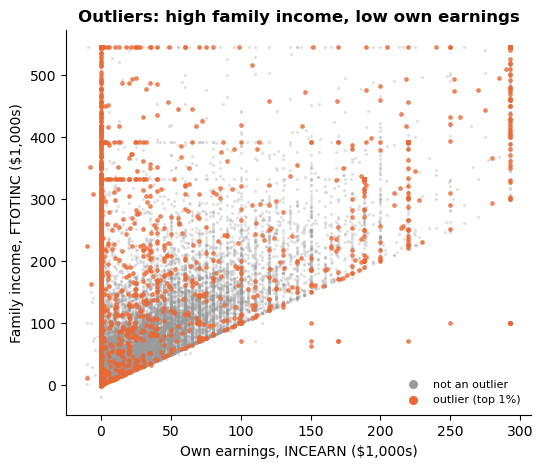

In [25]:
inc = df.loc[train, ["INCEARN", "FTOTINC"]].to_numpy() / 1000
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(inc[normal_s, 0], inc[normal_s, 1], s=2, alpha=0.2, color=GREY, label="not an outlier")
ax.scatter(inc[out_s, 0], inc[out_s, 1], s=6, alpha=0.7, color=ORANGE, label=f"outlier (top {OUT_SHARE:.0%})")
leg = ax.legend(fontsize=8, frameon=False)
for h in getattr(leg, "legend_handles", getattr(leg, "legendHandles", [])):
    h.set_sizes([30]); h.set_alpha(1)
ax.set_xlabel("Own earnings, INCEARN ($1,000s)"); ax.set_ylabel("Family income, FTOTINC ($1,000s)")
ax.set_title("Outliers: high family income, low own earnings", fontweight="bold")
# save_fig(fig, "outliers_income_scatter")

## 7. Save results

In [ ]:
sweep.to_csv(OUT_DIR / "kmeans_choose_k.csv")
final_scores.to_csv(OUT_DIR / "kmeans_final_scores.csv")
profile.join(top_levels).to_csv(OUT_DIR / "kmeans_cluster_profile.csv")
by_year.to_csv(OUT_DIR / "kmeans_divorce_rate_by_cluster_year.csv")
centres.to_csv(OUT_DIR / "kmeans_centres.csv", index_label="cluster")
pd.DataFrame({"row": np.arange(len(df)), "SPLIT": df["SPLIT"], "cluster": cluster_all}).to_csv(
    OUT_DIR / "kmeans_labels.csv", index=False)
print("Saved to", OUT_DIR.resolve())
for p in sorted(OUT_DIR.rglob("*.*")):
    print("  ", p.relative_to(OUT_DIR))

Saved to /Users/ivanpostolov/Downloads/report_outputs/clustering
   figures/kmeans_choose_k.png
   figures/kmeans_divorce_rate_by_cluster.png
   figures/kmeans_numeric_centres.png
   figures/kmeans_pca_scatter.png
   kmeans_centres.csv
   kmeans_choose_k.csv
   kmeans_cluster_profile.csv
   kmeans_divorce_rate_by_cluster_year.csv
   kmeans_final_scores.csv
   kmeans_labels.csv


## Notes for the report

* **Why k-means fits here, and where it does not.** It scales to millions of rows (seconds per fit), which most
  alternatives do not. But it assumes compact, roughly round clusters of similar size and uses Euclidean distance.
  On one-hot columns that distance is crude, and the numeric z-scores carry most of the variance (table in
  Section 2), so they drive the clusters.
* **Expect modest indices.** Survey respondents form a continuum rather than separate groups, so silhouette values
  well below 0.5 are normal. Report the indices together and use the divorce rate by cluster to show whether the
  clusters are useful.
* **Other algorithms.** DBSCAN and hierarchical clustering need memory that grows with the square of the number of
  rows, so they cannot run on all rows in Colab. Run them on a sample of 20–50k rows and say so.